DATA ANALYSIS PYTHON PROJECT - GROCERY ANALYSIS

In [77]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [78]:
df = pd.read_excel(r"C:\Users\Dell\Desktop\pandas\GroceryData.xlsx")



In [79]:
df.head(10)


,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0
5,low fat,FDS52,Frozen Foods,2020,OUT017,Tier 2,Small,Supermarket Type1,0.005505,8.89,102.4016,5.0
6,Low Fat,NCU05,Health and Hygiene,2011,OUT010,Tier 3,Small,Grocery Store,0.098312,11.80,81.4618,5.0
7,Low Fat,NCD30,Household,2015,OUT045,Tier 2,Small,Supermarket Type1,0.026904,19.70,96.0726,5.0
8,Low Fat,FDW20,Fruits and Vegetables,2014,OUT013,Tier 3,High,Supermarket Type1,0.024129,20.75,124.1730,5.0
9,Low Fat,FDX25,Canned,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.101562,NaN,181.9292,5.0


In [80]:
df.tail(10)

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
8513,Regular,DRY23,Soft Drinks,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.108568,NaN,42.9112,4.0
8514,low fat,FDA11,Baking Goods,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.043029,NaN,94.7436,4.0
8515,low fat,FDK38,Canned,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.053032,NaN,149.1734,4.0
8516,low fat,FDO38,Canned,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.072486,NaN,78.9986,4.0
8517,low fat,FDG32,Fruits and Vegetables,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.175143,NaN,222.3772,4.0
8518,low fat,NCT53,Health and Hygiene,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.000000,NaN,164.5526,4.0
8519,low fat,FDN09,Snack Foods,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.034706,NaN,241.6828,4.0
8520,low fat,DRE13,Soft Drinks,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.027571,NaN,86.6198,4.0
8521,reg,FDT50,Dairy,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.107715,NaN,97.8752,4.0
8522,reg,FDM58,Snack Foods,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.000000,NaN,112.2544,4.0


In [81]:
df.shape

(8523, 12)

In [82]:
df.columns


Index(['Item Fat Content', 'Item Identifier', 'Item Type',
       'Outlet Establishment Year', 'Outlet Identifier',
       'Outlet Location Type', 'Outlet Size', 'Outlet Type', 'Item Visibility',
       'Item Weight', 'Sales', 'Rating'],
      dtype='object')

In [83]:
df.dtypes

Item Fat Content              object
Item Identifier               object
Item Type                     object
Outlet Establishment Year      int64
Outlet Identifier             object
Outlet Location Type          object
Outlet Size                   object
Outlet Type                   object
Item Visibility              float64
Item Weight                  float64
Sales                        float64
Rating                       float64
dtype: object

In [84]:
print(df['Item Fat Content'].unique())

['Regular' 'Low Fat' 'low fat' 'LF' 'reg']


In [85]:
df['Item Fat Content'] =df['Item Fat Content'] .replace({'LF':'Low Fat', 'low Fat':'Low Fat','reg':'Regular'})

In [86]:
print(df['Item Fat Content'].unique())

['Regular' 'Low Fat' 'low fat']


business requirement


kpi requirements

In [87]:
#total sales
total_sales = df['Sales'].sum()
#average sales
average_sales = df['Sales'].mean()
#no of ite sold
no_of_items_sold=df['Sales'].count()
#average rating 
avg_rating=df['Rating'].mean()

#display
print(f"total sales:${total_sales:,.1f}")
print(f"average sales:${average_sales:,.1f}")
print(f"no_of_item_sold:{no_of_items_sold:,.1f}")
print(f"avg_rating:{avg_rating:,.1f}")


total sales:$1,201,681.5
average sales:$141.0
no_of_item_sold:8,523.0
avg_rating:4.0


### **charts requirement**


total sale by fat content


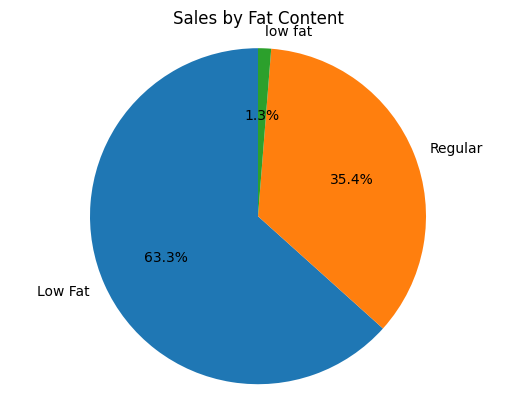

In [88]:
sales_by_fat = df.groupby('Item Fat Content')['Sales'].sum()

plt.pie(
    sales_by_fat,
    labels=sales_by_fat.index,
    autopct='%.1f%%',
    startangle=90
)

plt.title('Sales by Fat Content')
plt.axis('equal')
plt.show()


## **sales by item type**


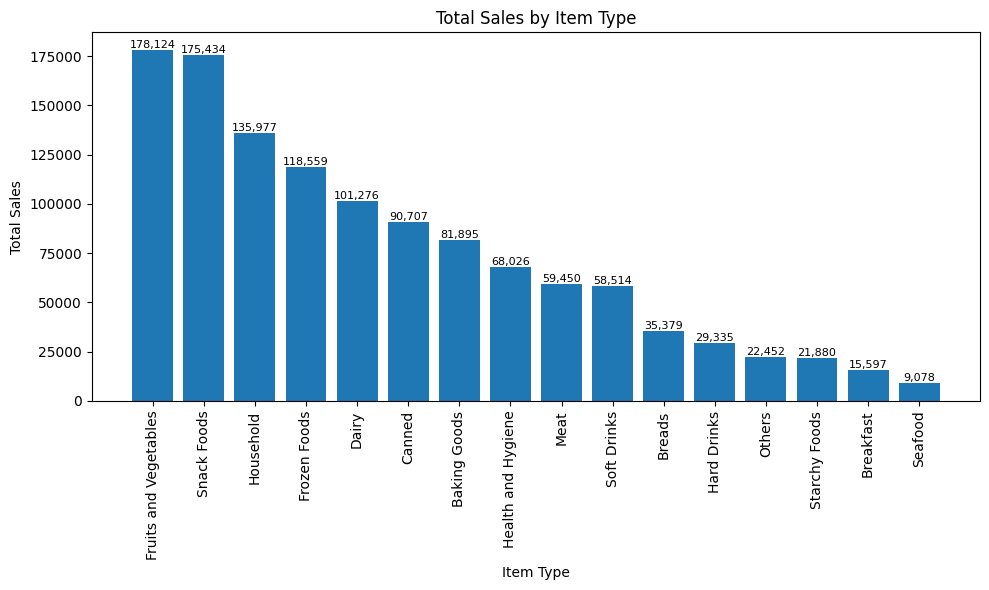

In [89]:
# Group the data by Item Type and calculate total sales for each item type
sales_by_type = (
    df.groupby('Item Type')['Sales']   # Group rows based on Item Type and select Sales column
      .sum()                            # Sum total sales for each Item Type
      .sort_values(ascending=False)     # Sort item types by sales in descending order
)

# Create a figure with specified width and height
plt.figure(figsize=(10, 6))

# Create a bar chart using item types on x-axis and total sales on y-axis
bars = plt.bar(sales_by_type.index, sales_by_type.values)

# Rotate x-axis labels for better readability
plt.xticks(rotation=90)

# Label the x-axis
plt.xlabel('Item Type')

# Label the y-axis
plt.ylabel('Total Sales')

# Set the title of the chart
plt.title('Total Sales by Item Type')

# Loop through each bar to display sales values on top of bars
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,  # Position text at the center of each bar
        bar.get_height(),                   # Position text at the top of the bar
        f'{bar.get_height():,.0f}',         # Format sales value with commas
        ha='center',                        # Horizontally center the text
        va='bottom',                        # Place text above the bar
        fontsize=8                          # Set font size
    )

# Adjust layout so labels and titles fit properly
plt.tight_layout()

# Display the bar chart
plt.show()


##  fat content by outlet for total sales

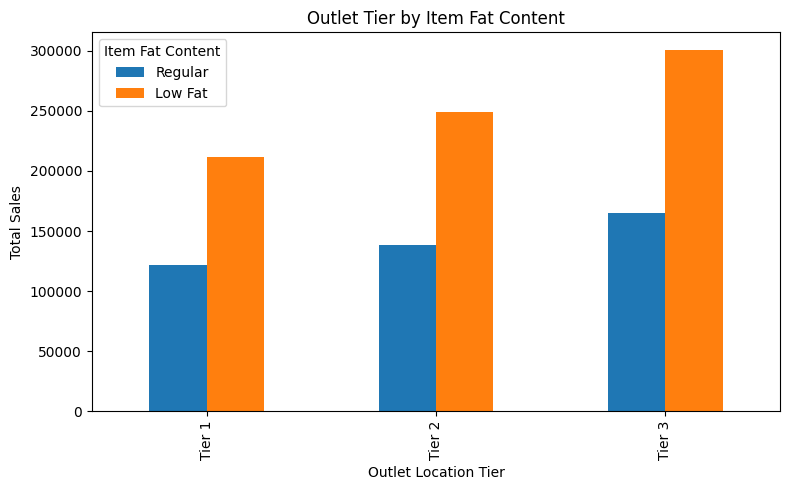

In [90]:
# Groups the dataset by outlet location type and item fat content
# and calculates the total sales for each combination
grouped = (
    df.groupby(['Outlet Location Type', 'Item Fat Content'])['Sales']
      .sum()
      .unstack()   # Converts Item Fat Content values into separate columns
)

# Keeps only Regular and Low Fat columns for comparison
grouped = grouped[['Regular', 'Low Fat']]

# Creates a grouped bar chart to compare sales
# of Regular vs Low Fat items across outlet tiers
ax = grouped.plot(
    kind='bar',
    figsize=(8, 5),
    title='Outlet Tier by Item Fat Content'
)

# Sets x-axis label
plt.xlabel('Outlet Location Tier')

# Sets y-axis label
plt.ylabel('Total Sales')

# Displays legend to identify Regular and Low Fat bars
plt.legend(title='Item Fat Content')

# Ensures labels and titles fit properly
plt.tight_layout()

# Shows the final plot
plt.show()


### **total sales by outlet establishment**


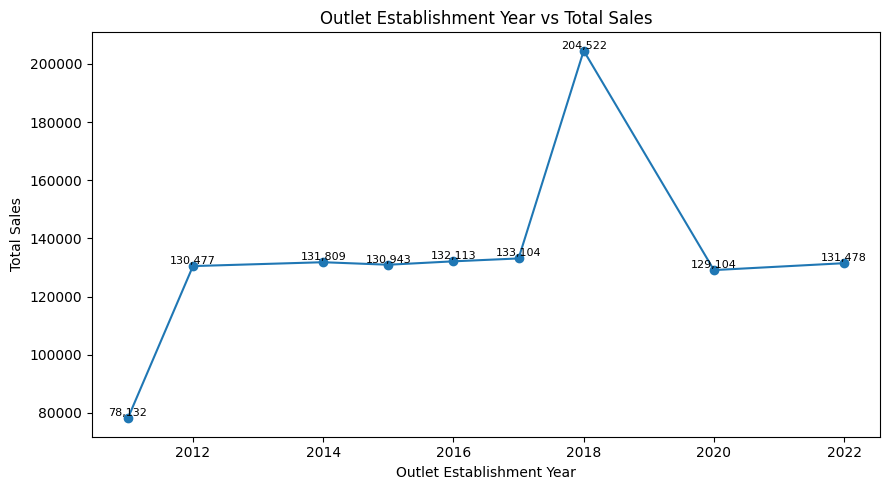

In [91]:
# Group data by Outlet Establishment Year and calculate total sales per year
sales_by_year = (
    df.groupby('Outlet Establishment Year')['Sales']
      .sum()
      .sort_index()
)

# Create the figure
plt.figure(figsize=(9, 5))

# Plot line chart
plt.plot(
    sales_by_year.index,
    sales_by_year.values,
    marker='o',
    linestyle='-'
)

# Label axes
plt.xlabel('Outlet Establishment Year')
plt.ylabel('Total Sales')

# Add title
plt.title('Outlet Establishment Year vs Total Sales')

# Add data labels on each point
for x, y in zip(sales_by_year.index, sales_by_year.values):
    plt.text(
        x, y,
        f'{y:,.0f}',   # format number with commas, no decimals
        ha='center',
        va='bottom',
        fontsize=8
    )

# Adjust layout to avoid overlapping
plt.tight_layout()

# Show the plot
plt.show()


## **sales by outlet size**

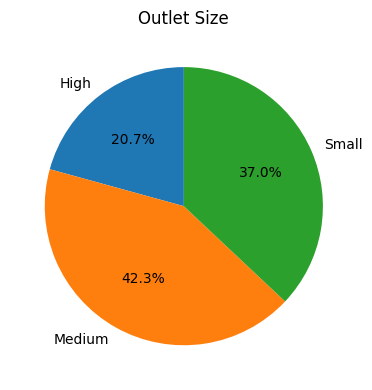

In [94]:
sales_by_size = df.groupby('Outlet Size')['Sales'].sum()
plt.figure(figsize =(4, 4)) # yo use gare paxi
plt.pie(
    sales_by_size,
    labels=sales_by_size.index,
    autopct='%.1f%%',
    startangle=90
)

plt.title('Outlet Size')
plt.tight_layout()#yo garna parxa
plt.show()

## **sales by outlet location**

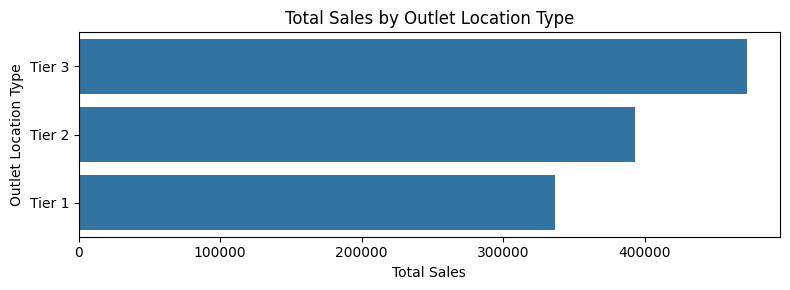

In [96]:
sales_by_location = (
    df.groupby('Outlet Location Type')['Sales']
      .sum()
      .reset_index()
)

sales_by_location = sales_by_location.sort_values(
    by='Sales',
    ascending=False
)

plt.figure(figsize=(8, 3))

ax = sns.barplot(
    data=sales_by_location,
    x='Sales',
    y='Outlet Location Type'
)

plt.xlabel('Total Sales')
plt.ylabel('Outlet Location Type')
plt.title('Total Sales by Outlet Location Type')


plt.tight_layout()
plt.show()
